# TED 03 — Modelagem Preditiva e Machine Learning
**Da Roça Inteligente — UNIBALSAS | ADS | 2026**

Notebook reproduzível baseado na metodologia descrita no Documento Técnico TED 03.
**Atenção:** este notebook foi organizado para execução; os resultados publicados no relatório são os registrados pela equipe, e não saídas previamente executadas deste arquivo. Execute todas as células para obter as métricas e imagens verificáveis.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

SAIDA = Path("resultados")
SAIDA.mkdir(exist_ok=True)
URL = "https://raw.githubusercontent.com/pedroigor-instaplayer/sistema-agroestoque/main/data/processed/retail_store_inventory_processed.csv"
dados = pd.read_csv(URL)
print("Base carregada:", dados.shape)
print(dados.columns.tolist())

Base carregada: (73100, 15)
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion', 'Competitor Pricing', 'Seasonality']


## 1. Preparação temporal
Cada registro é associado ao dia seguinte da mesma loja e do mesmo produto. Apenas dias consecutivos são mantidos. A coluna `Demand Forecast` não é usada como preditora para evitar dependência de uma variável altamente correlacionada com as vendas observadas.

In [2]:
dados["Date"] = pd.to_datetime(dados["Date"], errors="coerce")
dados = dados.dropna(subset=["Date"]).sort_values(["Store ID","Product ID","Date"]).copy()
grupos = dados.groupby(["Store ID","Product ID"], sort=False)
dados["Target_Date"] = grupos["Date"].shift(-1)
dados["Target_Units_Sold"] = grupos["Units Sold"].shift(-1)
dados = dados.loc[(dados["Target_Date"] - dados["Date"]).dt.days.eq(1)].copy()
mapa = {
    "Units Sold":"Prev_Units_Sold",
    "Inventory Level":"Prev_Inventory_Level",
    "Units Ordered":"Prev_Units_Ordered",
    "Price":"Prev_Price",
    "Discount":"Prev_Discount",
    "Competitor Pricing":"Prev_Competitor_Pricing"
}
dados = dados.rename(columns=mapa)
dados["Target_DayOfWeek"] = dados["Target_Date"].dt.dayofweek
dados["Target_Month"] = dados["Target_Date"].dt.month
numericas = list(mapa.values()) + ["Target_DayOfWeek","Target_Month"]
categoricas = ["Store ID","Product ID","Category","Region"]
X = dados[numericas+categoricas]
y = dados["Target_Units_Sold"]
print("Pares consecutivos:",len(dados))

Pares consecutivos: 73000


## 2. Divisão temporal e treinamento
As datas mais antigas compõem o treinamento e as mais recentes o teste. A divisão é feita por datas-alvo, não por sorteio de linhas.

In [3]:
datas = np.sort(dados["Target_Date"].unique())
limite = datas[int(len(datas)*0.8)]
treino = dados["Target_Date"] < limite
teste = ~treino
assert treino.sum()>0 and teste.sum()>0
preprocessador = ColumnTransformer([
    ("numericas",SimpleImputer(strategy="median"),numericas),
    ("categoricas",Pipeline([
        ("imputar",SimpleImputer(strategy="most_frequent")),
        ("onehot",OneHotEncoder(handle_unknown="ignore"))
    ]),categoricas)
])
modelo = Pipeline([
    ("preprocessamento",preprocessador),
    ("regressor",RandomForestRegressor(n_estimators=250,min_samples_leaf=2,max_features=0.8,random_state=42,n_jobs=-1))
])
modelo.fit(X.loc[treino],y.loc[treino])
previsto = modelo.predict(X.loc[teste])
baseline = dados.loc[teste,"Prev_Units_Sold"].to_numpy()
real = y.loc[teste].to_numpy()
print("Treino:",treino.sum(),"Teste:",teste.sum(),"Início teste:",pd.Timestamp(limite).date())

Treino: 58400 Teste: 14600 Início teste: 2023-08-09


## 3. Avaliação comparativa
Métricas do modelo e da referência simples (repetição das vendas do dia anterior). Os números devem ser confrontados com os valores documentados pela equipe; diferenças exigem revisão da preparação e da divisão temporal.

In [4]:
def metricas(nome, estimativa):
    return {"Modelo":nome,"MAE":mean_absolute_error(real,estimativa),
            "RMSE":np.sqrt(mean_squared_error(real,estimativa)),
            "R2":r2_score(real,estimativa)}
resultado = pd.DataFrame([metricas("Random Forest",previsto),metricas("Baseline — dia anterior",baseline)])
print(resultado.to_string(index=False))
resultado.to_csv(SAIDA/"TED03_metricas.csv",index=False)

                 Modelo        MAE       RMSE        R2
          Random Forest  89.871511 109.058257 -0.015077
Baseline — dia anterior 119.751507 153.505338 -1.011077


## 4. Gráficos produzidos pela execução
Os gráficos são gerados a partir das previsões efetivamente calculadas neste notebook.

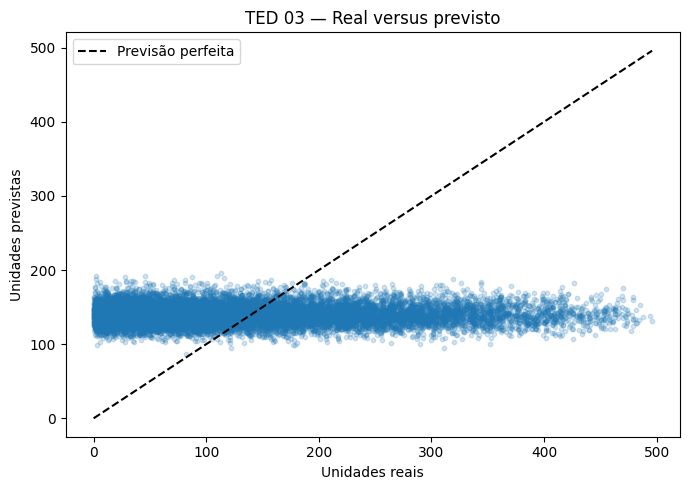

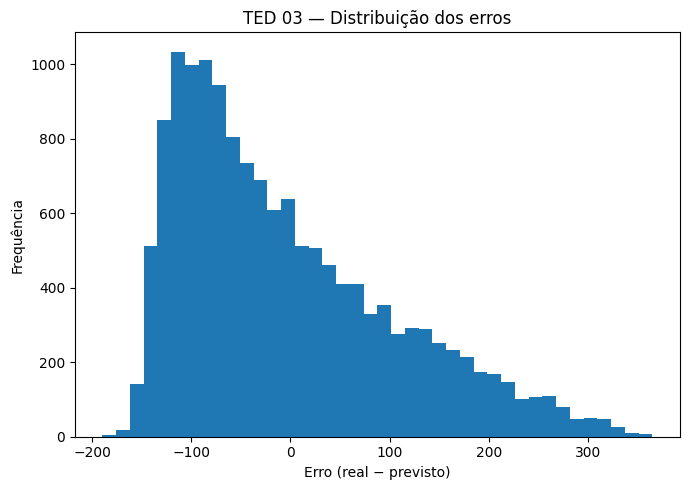

Resultados gravados em: /content/resultados


In [5]:
fig, ax=plt.subplots(figsize=(7,5))
ax.scatter(real,previsto,alpha=0.2,s=10)
lim=max(float(np.max(real)),float(np.max(previsto)))
ax.plot([0,lim],[0,lim],linestyle="--",color="black",label="Previsão perfeita")
ax.set(xlabel="Unidades reais",ylabel="Unidades previstas",title="TED 03 — Real versus previsto")
ax.legend()
fig.tight_layout()
fig.savefig(SAIDA/"TED03_real_vs_previsto.png",dpi=170)
plt.show()

erros=real-previsto
fig,ax=plt.subplots(figsize=(7,5))
ax.hist(erros,bins=40)
ax.set(xlabel="Erro (real − previsto)",ylabel="Frequência",title="TED 03 — Distribuição dos erros")
fig.tight_layout()
fig.savefig(SAIDA/"TED03_distribuicao_erros.png",dpi=170)
plt.show()
print("Resultados gravados em:",SAIDA.resolve())

## 5. Interpretação
O desempenho deve ser interpretado comparando o Random Forest com o baseline e com a referência de média expressa pelo R². Um R² negativo significa desempenho inferior à previsão constante pela média do alvo na amostra avaliada. A base é sintética e não demonstra precisão na operação real da empresa.